<a href="https://colab.research.google.com/github/uhar0562-dev/Airbnb-Price-prediction/blob/main/AIML_MP2%2C2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [18]:
df = pd.read_csv("/content/AB_NYC_2019.csv")

In [19]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [20]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [22]:
# Basic preprocessing to define X and y
# Let's drop columns that are irrelevant or have too many missing values for a quick model, and fill missing numeric values.
df_clean = df.drop(columns=['id', 'name', 'host_id', 'host_name', 'last_review'])

# Fill missing values for numerical and categorical columns
df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)
df_clean['neighbourhood_group'] = df_clean['neighbourhood_group'].fillna('Unknown')
df_clean['neighbourhood'] = df_clean['neighbourhood'].fillna('Unknown')
df_clean['room_type'] = df_clean['room_type'].fillna('Unknown')

# One-hot encode categorical features
df_encoded = pd.get_dummies(df_clean, columns=['neighbourhood_group', 'neighbourhood', 'room_type'], drop_first=True)

# Define target (price) and features
y = df_encoded['price']
X = df_encoded.drop(columns=['price'])

print("Shape of features X:", X.shape)
print("Shape of target y:", y.shape)

Shape of features X: (48895, 233)
Shape of target y: (48895,)


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (39116, 233)
Testing data: (9779, 233)


In [24]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print("Model training completed")

Model training completed


In [25]:
y_pred = model.predict(X_test)
print("Actual prices:")
print(y_test.head())
print("Predicted prices:")
print(y_pred[:5])

Actual prices:
879       89
44383     30
15394    120
43230    470
16332    199
Name: price, dtype: int64
Predicted prices:
[161.59388752  47.52264207 127.36902671 214.79590924 173.39343836]


In [26]:
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("R-Squared:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

R-Squared: 0.13585820865398857
MAE: 68.14742838247919
MSE: 38228.110156687064
RMSE: 195.5201016690792


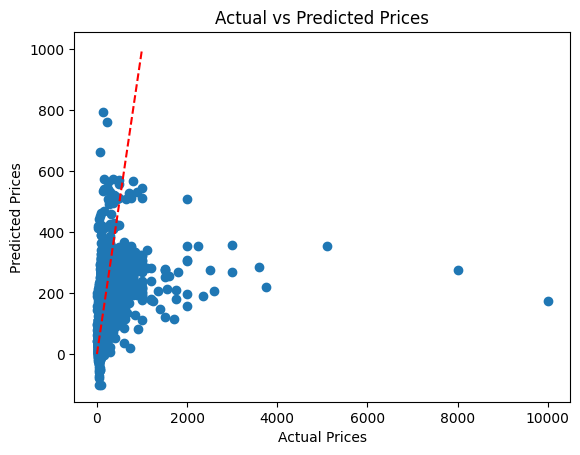

In [27]:
import matplotlib.pyplot as plt
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices")
# Perfect prediction line
plt.plot([0, 1000], [0, 1000], 'r--')
plt.show()

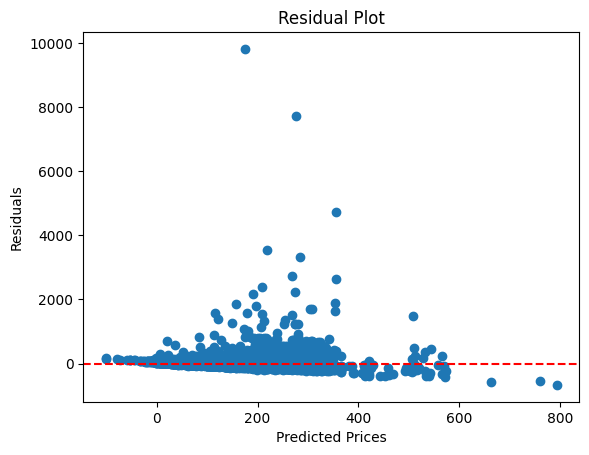

In [28]:
residuals = y_test - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [29]:
results = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

results['Error'] = abs(
    results['Actual Price'] - results['Predicted Price']
)

results['Price Group'] = pd.cut(
    results['Actual Price'],
    bins=[-1, 100, 300, float('inf')],
    labels=['Cheap', 'Medium', 'Expensive']
)

print(results.groupby('Price Group', observed=True)['Error'].mean())

Price Group
Cheap         42.380090
Medium        56.226619
Expensive    346.085925
Name: Error, dtype: float64
